In [1]:
%load_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import sys
import numpy as np
# import matplotlib.pyplot as plt

code_path = "../src" # linux
sys.path.append(code_path)
sys.path.append(code_path+"/src")

import utilities as util
from xai_video_gradmap_interface import GRAD4VAD_XAI_PPA

%matplotlib inline

/home/mulugetawa/AI4CITIZENS/PACA /home/mulugetawa/AI4CITIZENS/PACA//src// /home/mulugetawa/AI4CITIZENS/PACA//data//
torch:  2.5 ; cuda:  cu124
process time: 0.000010 seconds.
process time: 0.000000 seconds.


## Load XAI MAP System: CLIP Prompts [LLM]

In [2]:
xai_clip_modelname = ["ViT-B/16", "ViT-B/32", "ViT-L/14", "ViT-L/14@336px"][2]
xai_anml_cat_list = None
ADXAIMAP_PPA_Obj = GRAD4VAD_XAI_PPA(xai_clip_modelname=xai_clip_modelname,
                                    xai_anml_cat_list=xai_anml_cat_list,
                                    concept_json_filepath=r"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/llmv2_custom-concept.json",
                                    prompt_feature_np_filepath=rf"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/anml_class_prompt_llm_clip_features_norm_llmv2_custom_{xai_clip_modelname.replace('-','').replace('/','')}.npy",
                                    device="cuda"
                                    )

CLIP4VAD_XAI init...
Model parameters: 427616513
Input resolution: 224
Kernel size: (14, 14)
Context length: 77
Vocab size: 49408
Pooling method: max
CLIP image preprocess function:  Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7fc4f1101c60>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Loading Pre-computed Normalized CLIP text embedding....
CLIP Prompt Anomaly Categories: ['violence', 'burglary', 'arson', 'assault', 'explosion', 'gun_holding', 'gun_shooting', 'knife_holding', 'knife_stabbing', 'riot', 'crowd_density', 'person falling', 'car_accident', 'vandalism', 'normal_car_driving', 'children_playing', 'normal_activity']
anml_class_prompt_clip_features_norm: torch.Size([768, 17]), min:-0.5789034366607666, max:0.522716760635376
MAP anml_text_prompt_embedding: torch.Size([768, 17])
Processing GRAD4VAD_XAI.

### XAI MAP Inference: cctv_weapon_dataset

#### Load test image

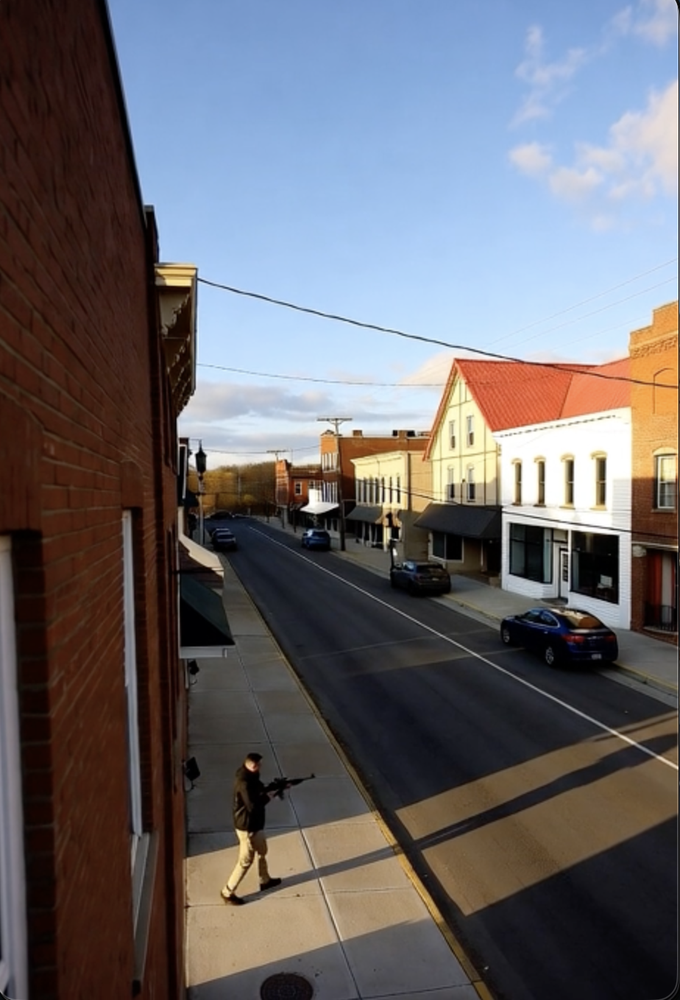

(1358, 924, 3)

In [3]:
xai_cat_name = "gun_shooting"
image_filepath = r"/home/mulugetawa/AI4CITIZENS/Datasets/Simuletic/cctv_weapon_dataset/images/Scene6_4.png"
image_pil = util.PIL.Image.open(image_filepath).convert("RGB") # rgb
image_pil
# image_pil.thumbnail((640, 640), util.PIL.Image.Resampling.LANCZOS) 
image_arr_rgb = np.asarray(image_pil)
image_arr_rgb.shape

#### Using Grad-ECLIP

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6


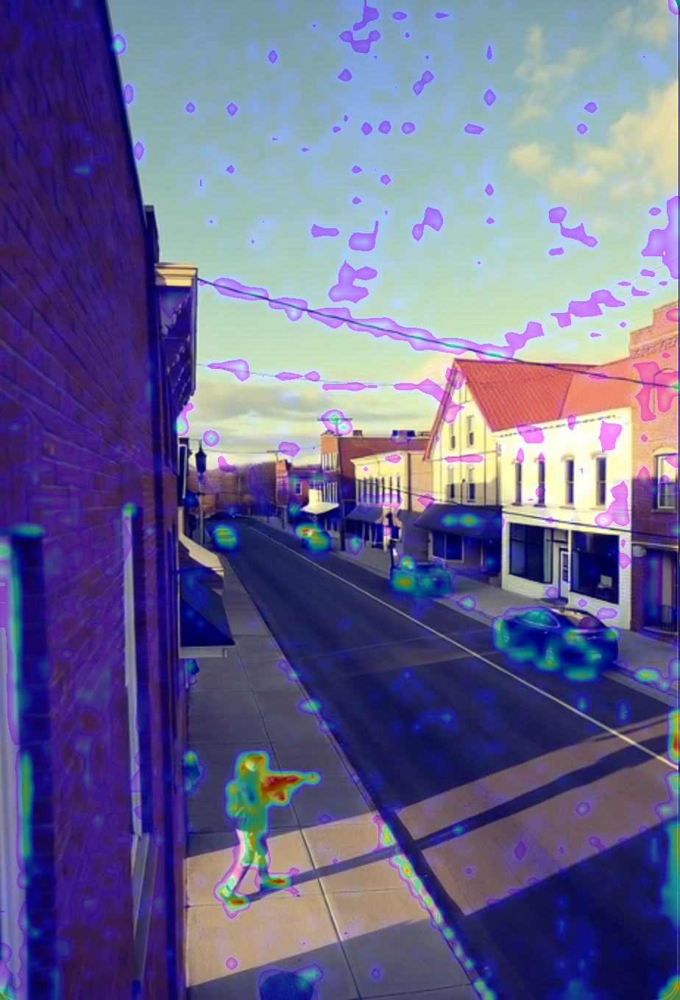

In [4]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#######Using Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6


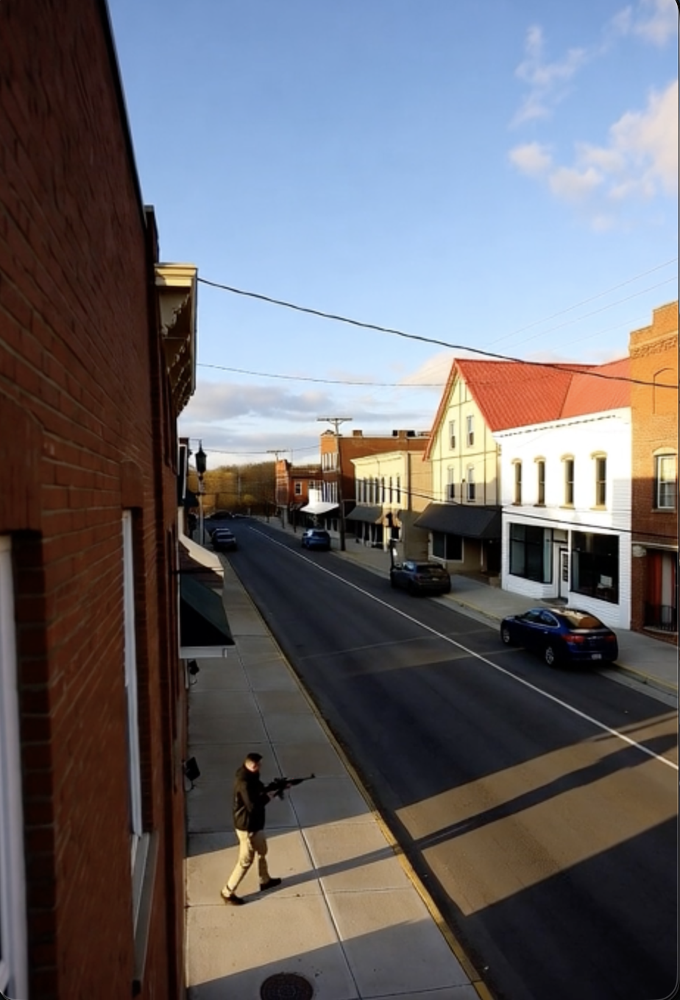

In [5]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running patch sliding window accuracy up...
imsize: (924, 1358), resize_wh: None
image_arr: (1358, 924, 3)
patch_size: 448
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12


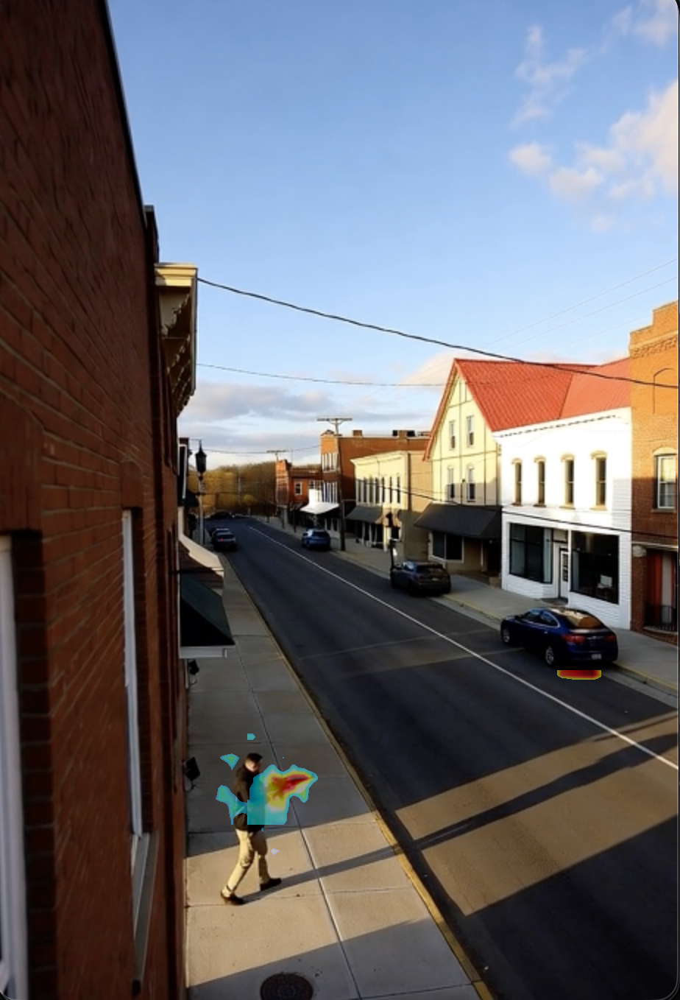

In [6]:
autofocus_method = "ppa_patch_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching (PPA) + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
ADXAIDetector.inference: 
Processing ADXAIDetector.inference: 
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
CLIP4VAD_XAI.clip_video_encoder: 
Processing CLIP4VAD_XAI.clip_video_encoder: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
CLIP4VAD_XAI.clip_video_preprocessor: 
Processing CLIP4VAD_XAI.clip_video_preprocessor: 
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 106.29it/s]


CLIP4VAD_XAI.clip_video_preprocessor is done!
process time: 0.116657 seconds.
CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 36.53it/s]

CLIP4VAD_XAI.clip_video_encoder is done!
process time: 0.147164 seconds.


Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.205936 seconds.
ADXAIDetector.inference is done!
process time: 0.206010 seconds.


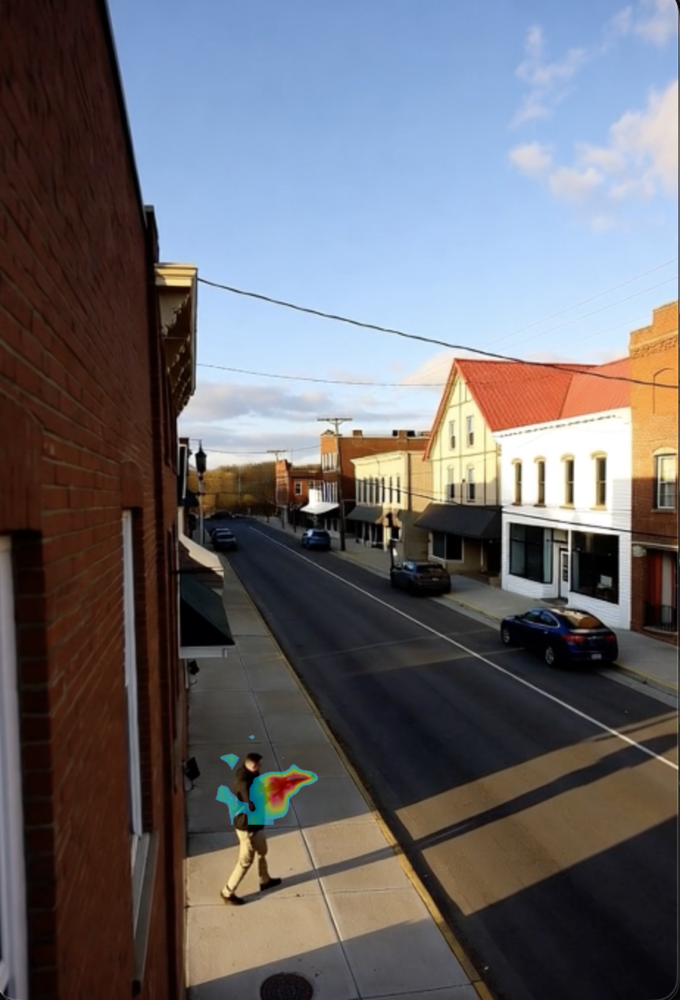

In [7]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

### XAI MAP Inference: cctv_knife_dataset

#### Load test image

(916, 1358)

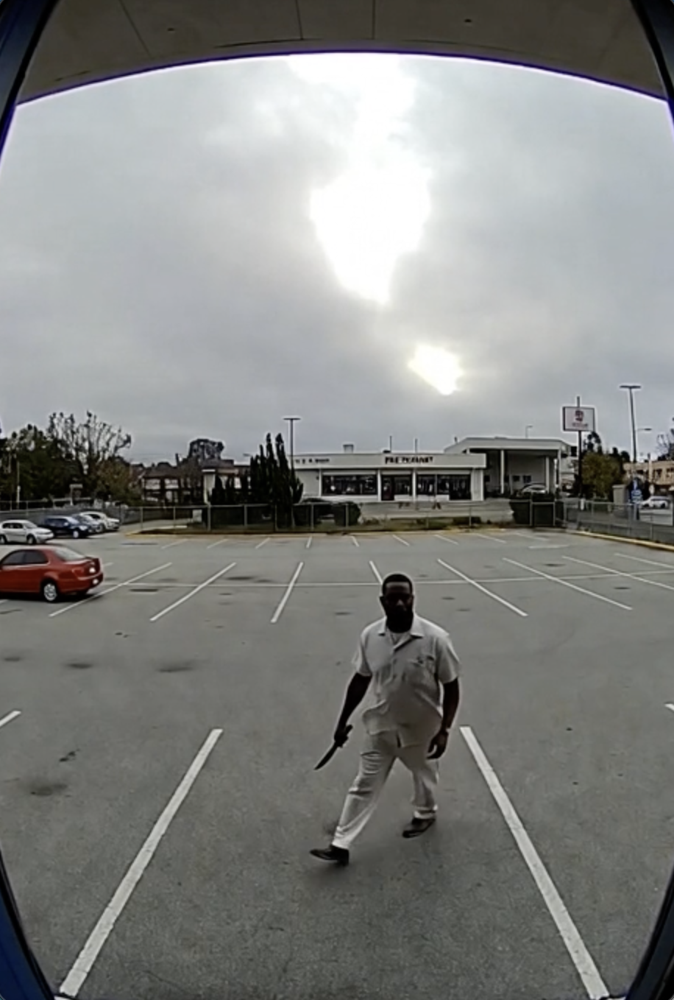

In [8]:
xai_cat_name = "knife_holding"
image_filepath = r"/home/mulugetawa/AI4CITIZENS/Datasets/Simuletic/cctv_knife_dataset/images/Knife_scenario_98.png"
image_pil = util.PIL.Image.open(image_filepath).convert("RGB") # rgb
image_pil.size
image_pil
# image_pil.thumbnail((640, 640), util.PIL.Image.Resampling.LANCZOS) 
image_arr_rgb = np.asarray(image_pil)

#### Using Grad-ECLIP

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7


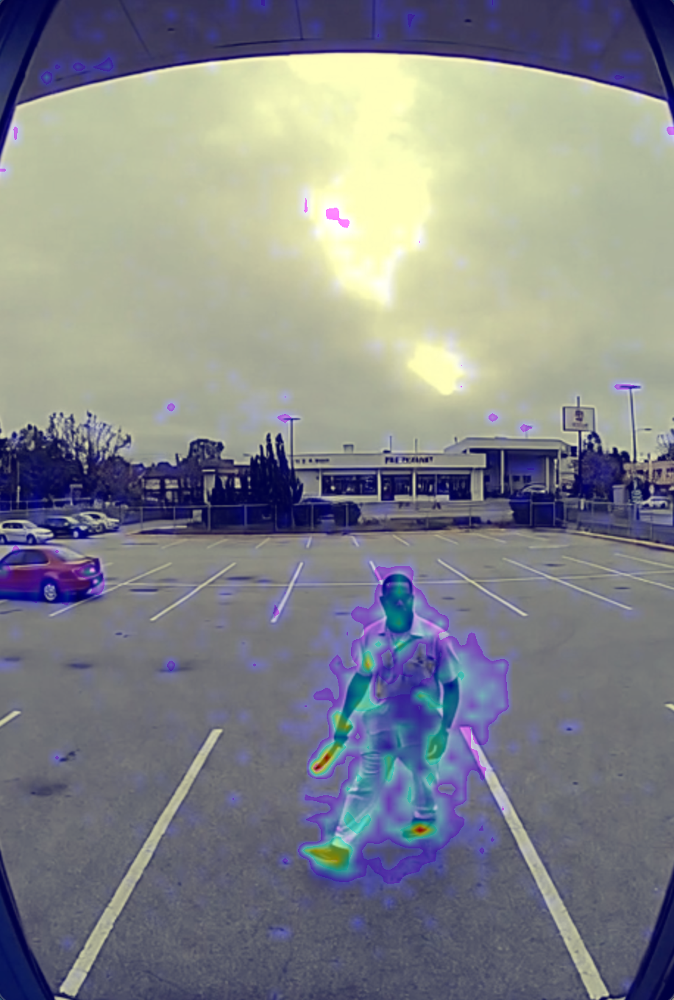

In [9]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7


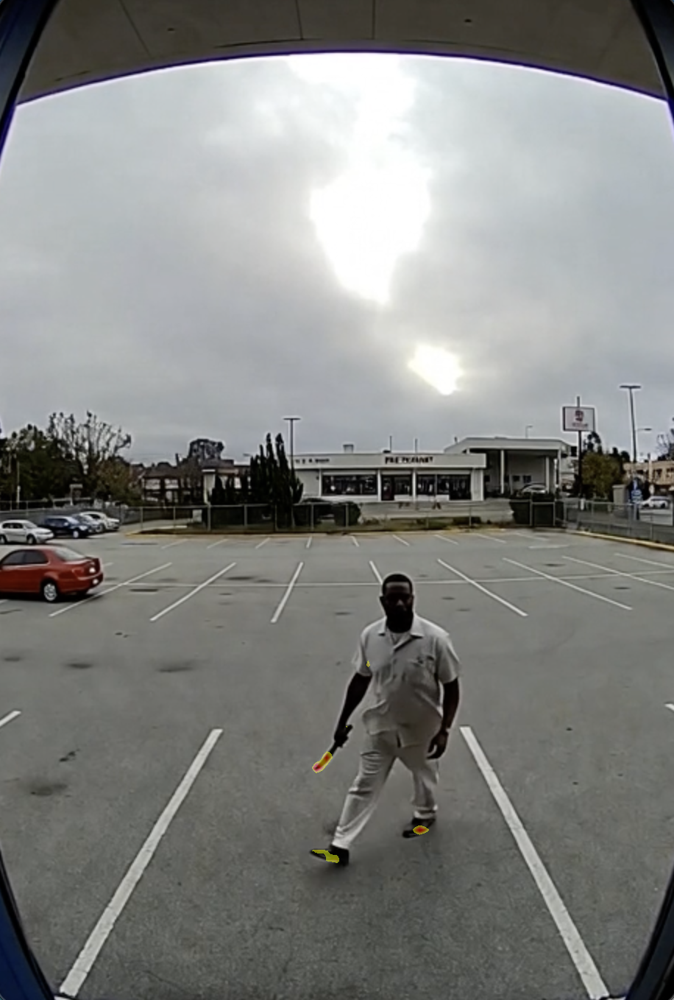

In [10]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running patch sliding window accuracy up...
imsize: (916, 1358), resize_wh: None
image_arr: (1358, 916, 3)
patch_size: 448
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12


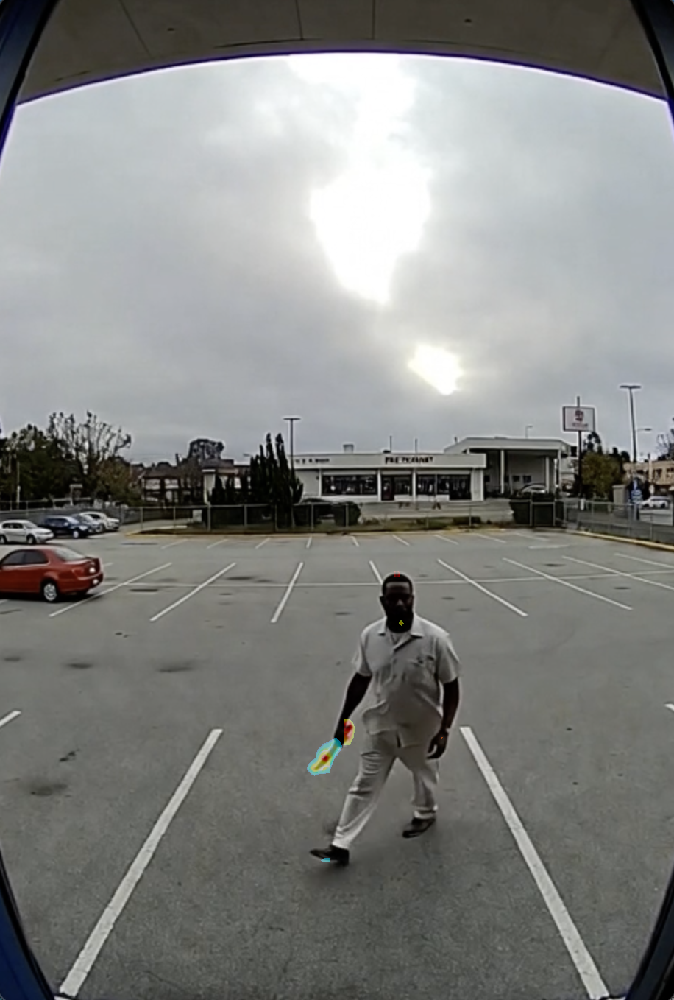

In [11]:
autofocus_method = "ppa_patch_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching (PPA) + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
ADXAIDetector.inference: 
Processing ADXAIDetector.inference: 
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
CLIP4VAD_XAI.clip_video_encoder: 
Processing CLIP4VAD_XAI.clip_video_encoder: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
CLIP4VAD_XAI.clip_video_preprocessor: 
Processing CLIP4VAD_XAI.clip_video_preprocessor: 
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 155.61it/s]


CLIP4VAD_XAI.clip_video_preprocessor is done!
process time: 0.079932 seconds.
CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 50.35it/s]

CLIP4VAD_XAI.clip_video_encoder is done!
process time: 0.102999 seconds.
Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.106774 seconds.
ADXAIDetector.inference is done!
process time: 0.106823 seconds.


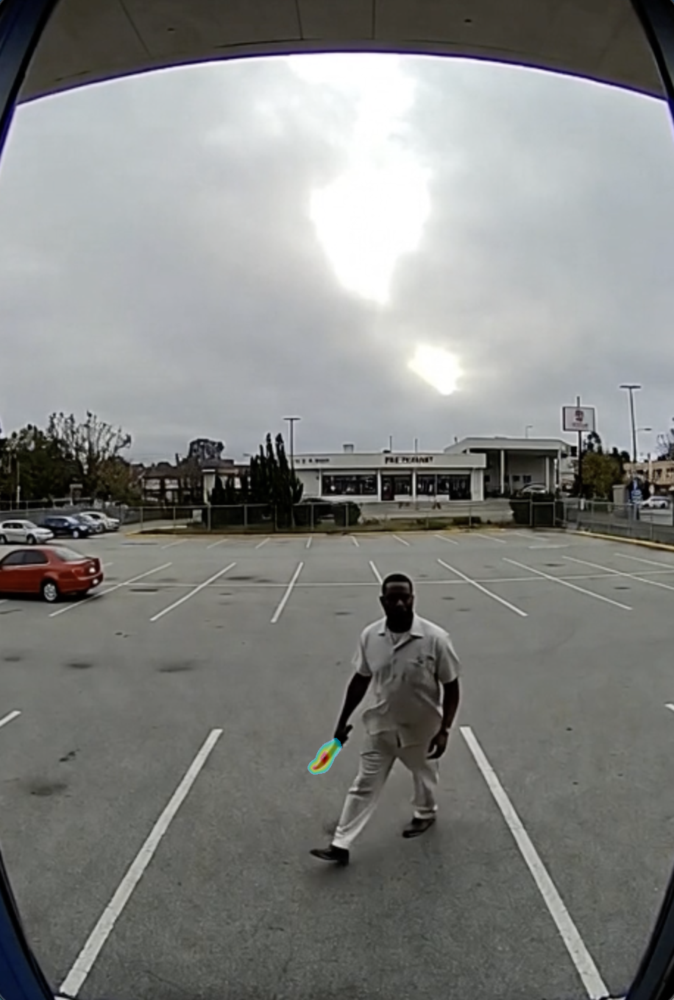

In [12]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

## Load XAI MAP System: : CLIP Prompts [Keyword]

In [13]:
xai_anml_cat_list = ["gun_holding", "gun_shooting", "knife_holding", "knife_stabbing"]
xai_clip_modelname = ["ViT-B/16", "ViT-B/32", "ViT-L/14", "ViT-L/14@336px"][2]
ADXAIMAP_PPA_Obj = GRAD4VAD_XAI_PPA(xai_clip_modelname=xai_clip_modelname,
                                    xai_anml_cat_list=xai_anml_cat_list,
                                    concept_json_filepath=r"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/llmv2_custom-concept.json",
                                    prompt_feature_np_filepath=rf"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/anml_class_prompt_llm_clip_features_norm_llmv2_custom_{xai_clip_modelname.replace('-','').replace('/','')}.npy",
                                    device="cuda"
                                    )

xai_anml_cat_list: ['gun_holding', 'gun_shooting', 'knife_holding', 'knife_stabbing']
CLIP4VAD_XAI init...
Model parameters: 427616513
Input resolution: 224
Kernel size: (14, 14)
Context length: 77
Vocab size: 49408
Pooling method: max
CLIP image preprocess function:  Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7fc4f1101c60>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Generating CLIP text embedding....
CLIP Prompt Anomaly Categories: ['gun_holding', 'gun_shooting', 'knife_holding', 'knife_stabbing']
anml_class_prompt_clip_features_norm: torch.Size([768, 4]), min:-0.5326099991798401, max:0.5044054985046387
MAP anml_text_prompt_embedding: torch.Size([768, 4])
Processing GRAD4VAD_XAI.__init__: 
GRAD4VAD_XAI.__init__ is done!


### XAI MAP Inference: cctv_weapon_dataset

#### Load test image

In [14]:
xai_cat_name = "gun_shooting"
image_filepath = r"/home/mulugetawa/AI4CITIZENS/Datasets/Simuletic/cctv_weapon_dataset/images/Scene6_4.png"
image_pil = util.PIL.Image.open(image_filepath).convert("RGB") # rgb
image_arr_rgb = np.asarray(image_pil)
image_arr_rgb.shape

(1358, 924, 3)

#### Using Grad-ECLIP

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 1


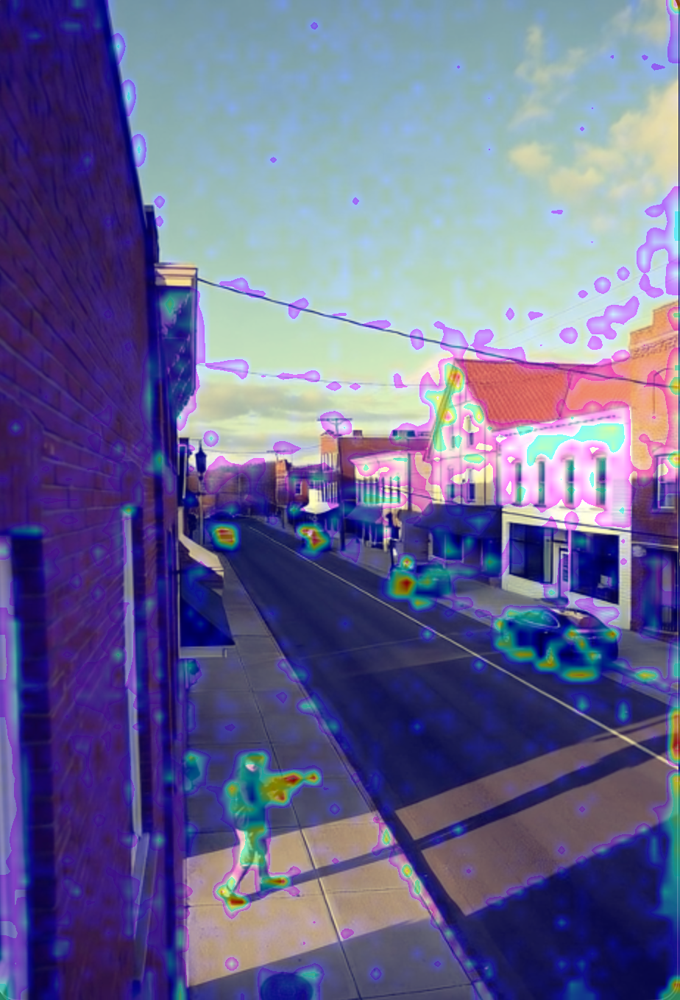

In [15]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 1


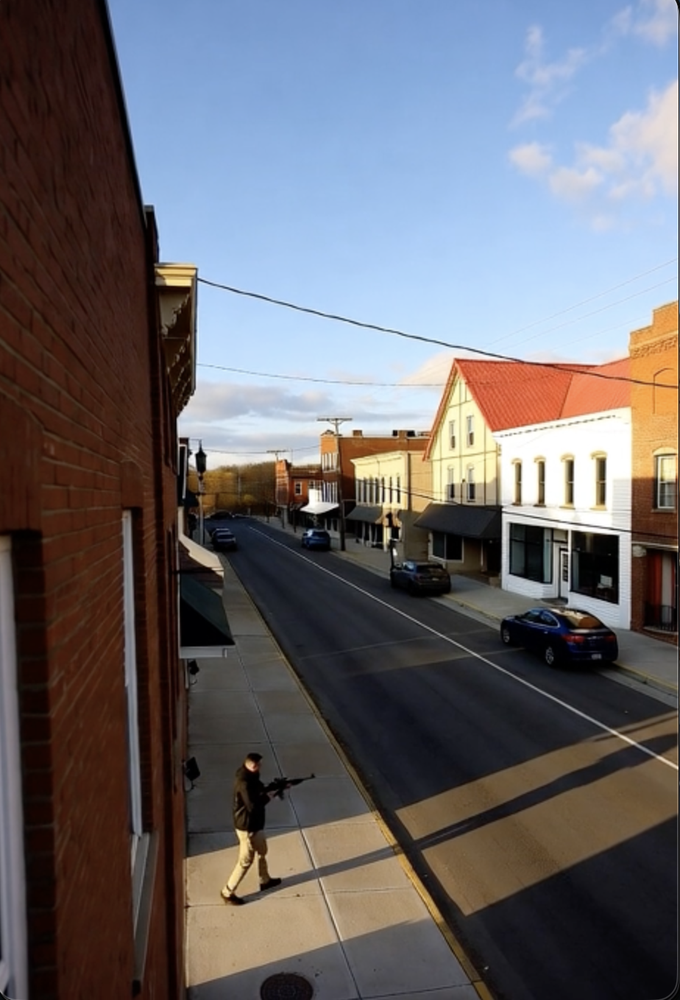

In [16]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 1
Running patch sliding window accuracy up...
imsize: (924, 1358), resize_wh: None
image_arr: (1358, 924, 3)
patch_size: 448
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12


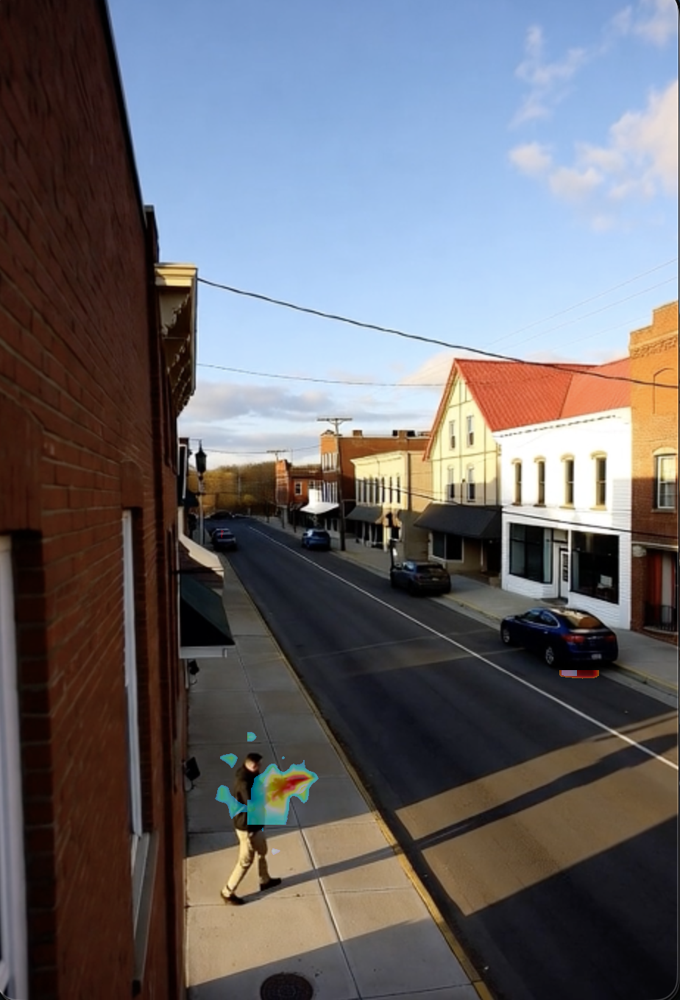

In [17]:
autofocus_method = "ppa_patch_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching (PPA) + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 1
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
ADXAIDetector.inference: 
Processing ADXAIDetector.inference: 
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
CLIP4VAD_XAI.clip_video_encoder: 
Processing CLIP4VAD_XAI.clip_video_encoder: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
CLIP4VAD_XAI.clip_video_preprocessor: 
Processing CLIP4VAD_XAI.clip_video_preprocessor: 
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 75.67it/s]


CLIP4VAD_XAI.clip_video_preprocessor is done!
process time: 0.160852 seconds.
CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 43.34it/s]

CLIP4VAD_XAI.clip_video_encoder is done!
process time: 0.186624 seconds.
Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.191061 seconds.
ADXAIDetector.inference is done!
process time: 0.191103 seconds.


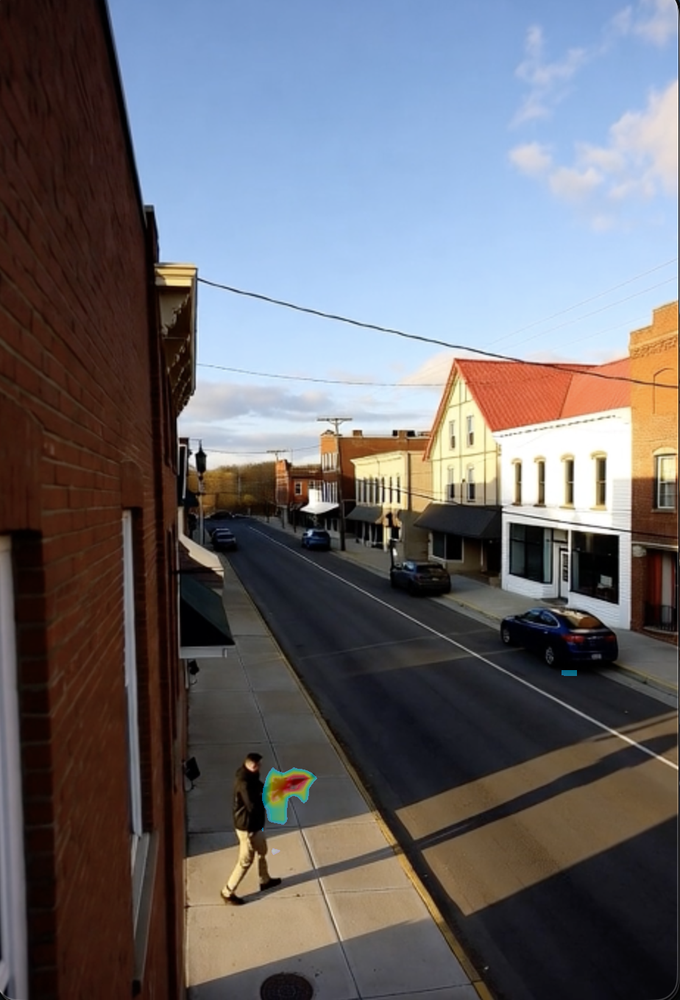

In [19]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

### XAI MAP Inference: cctv_knife_dataset

#### Load test image

In [20]:
xai_cat_name = "knife_holding"
image_filepath = r"/home/mulugetawa/AI4CITIZENS/Datasets/Simuletic/cctv_knife_dataset/images/Knife_scenario_98.png"
image_pil = util.PIL.Image.open(image_filepath).convert("RGB") # rgb
image_arr_rgb = np.asarray(image_pil)
image_arr_rgb.shape

(1358, 916, 3)

#### Using Grad-ECLIP

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 2


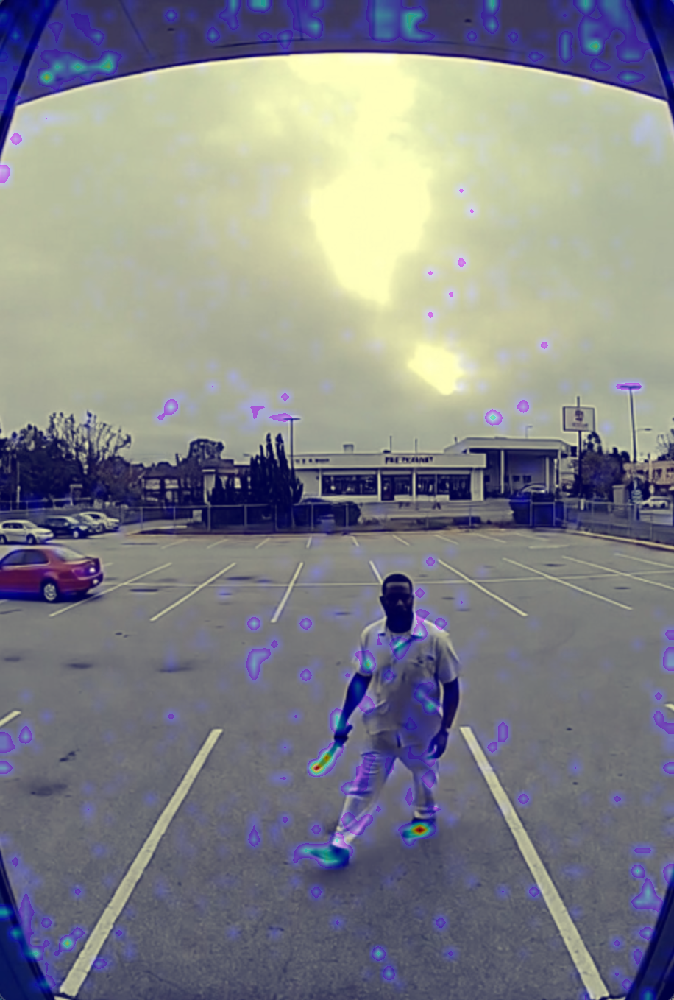

In [21]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 2


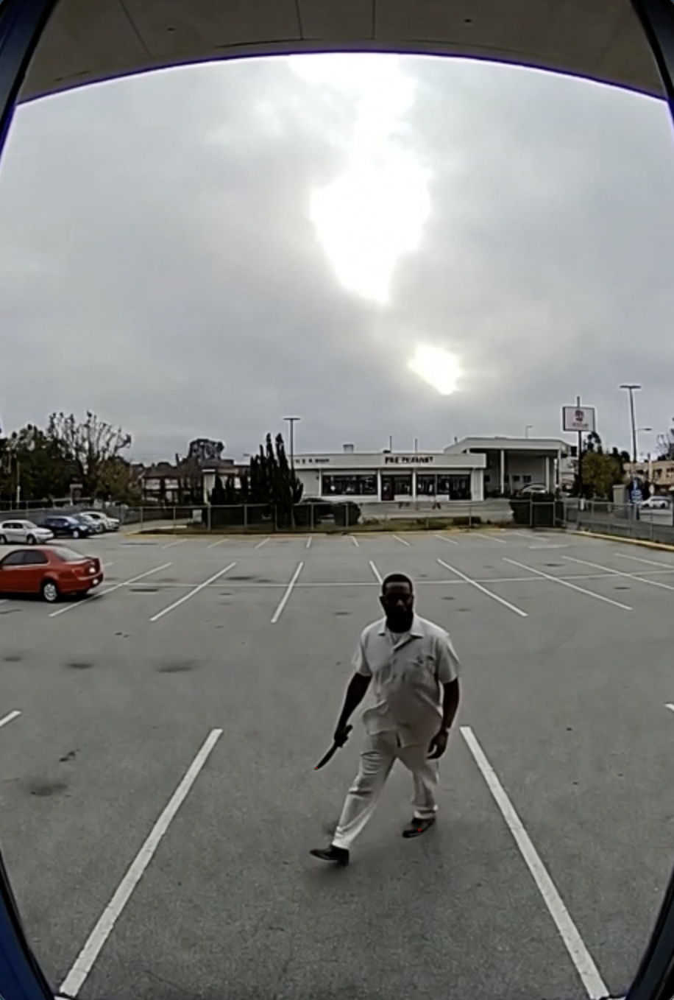

In [22]:
autofocus_method = "gradmap_only_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 2
Running patch sliding window accuracy up...
imsize: (916, 1358), resize_wh: None
image_arr: (1358, 916, 3)
patch_size: 448
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12


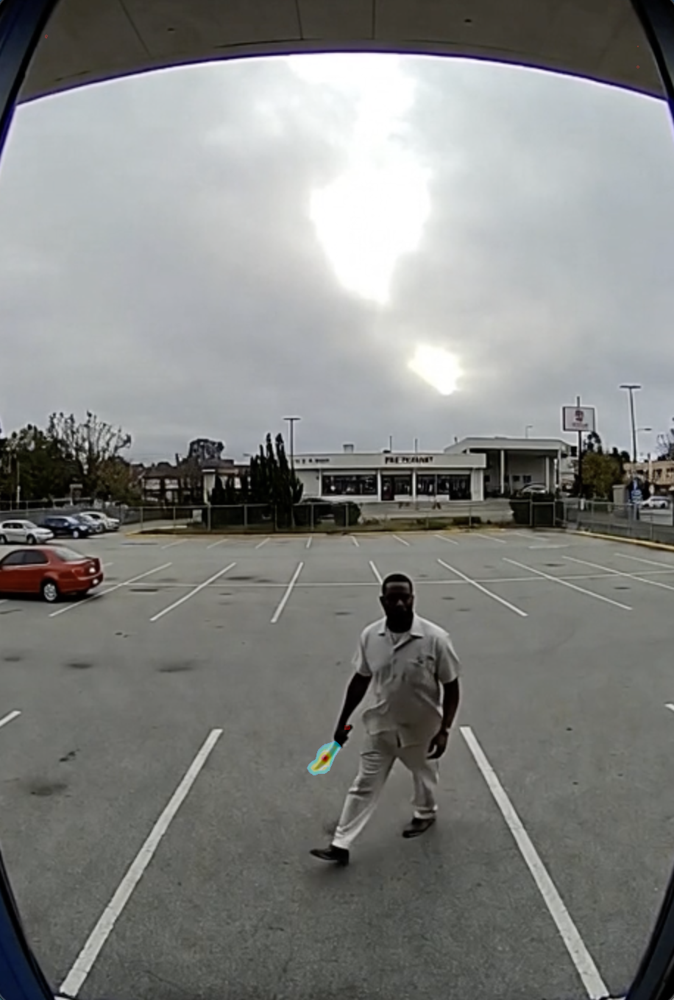

In [23]:
autofocus_method = "ppa_patch_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

#### Using Grid Patching (PPA) + Grad-ECLIP + Norm

config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 2
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
ADXAIDetector.inference: 
Processing ADXAIDetector.inference: 
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
CLIP4VAD_XAI.clip_video_encoder: 
Processing CLIP4VAD_XAI.clip_video_encoder: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
CLIP4VAD_XAI.clip_video_preprocessor: 
Processing CLIP4VAD_XAI.clip_video_preprocessor: 
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 122.31it/s]


CLIP4VAD_XAI.clip_video_preprocessor is done!
process time: 0.100897 seconds.
CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 39.42it/s]

CLIP4VAD_XAI.clip_video_encoder is done!
process time: 0.129431 seconds.
Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.133466 seconds.
ADXAIDetector.inference is done!
process time: 0.133512 seconds.


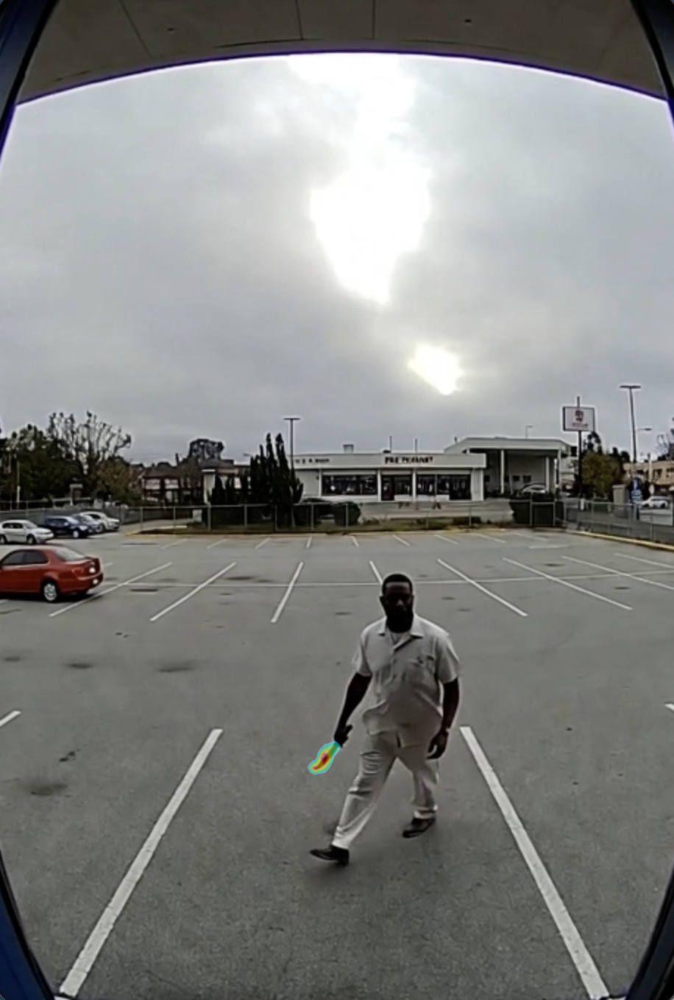

In [24]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(image_arr_rgb, 
                                    autofocus_method=autofocus_method,        
                                    xai_cat_name=xai_cat_name, 
                                    bbox_conf=0.50, ismultibox=False, 
                                    grad_mode="grad_eclip", 
                                    map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                    patch_size=448, step_size=336, 
                                    image_resize_wh=None, 
                                    isplot=True)
fig_pil

# Computational Cost Analysis

In [3]:
import pandas as pd
from collections import defaultdict

In [9]:
cc_compare_df["clip_modelname"].unique()

array(['ViT-B/32', 'ViT-L/14@336px', 'ViT-L/14', 'ViT-B/16'], dtype=object)

In [35]:
src_path = rf"/home/mulugetawa/AI4CITIZENS/Datasets/XD_Violence/ad_processed_cv2_BS_5_w320/PEL4VAD_AnonymizedAD_raw_image_RAW_FIX_adaptive_False/eval__cc_xai_cat"
def load_cc_results(src_path):
    result_files = [str(f) for f in util.Path(src_path).glob(f'*.json')]
    # print(result_files)
    cc_compare_dict = defaultdict(dict)
    for i, filepath in util.tqdm(enumerate(result_files)):
        filename = str(util.Path(filepath).name)
        dict_an_key = filepath.replace("cputime", "").replace("memory", "")
        
        # load json 
        result = util.load_json(filepath=filepath)
        # result
        if "usage" in filename:
            if "memory" in result:
                _result = {"memory_init":result["memory"]["memory_init"], "memory":result["memory"]["memory_increment"]}
                _ = result.pop("memory", None)
            elif "cputime" in result:    
                _result = {"cputime": result["cputime"]["time"]} 
                _ = result.pop("cputime", None)

        result["clip_modelname"] = result["clip_modelname"] + " (" + result["pooling_method"] + ")"
        
        cc_compare_dict[dict_an_key].update(result | _result)
        # break
    # cc_compare_dict
    cc_compare_df = pd.DataFrame.from_dict(cc_compare_dict).T.reset_index(drop=True)
    # cc_compare_df
    cc_compare_df[["cputime"]] = cc_compare_df[["cputime"]].astype(float).round(2)
    cc_compare_df[["memory_init", "memory"]] = cc_compare_df[["memory_init", "memory"]].astype(float).round(0)
    # print(cc_compare_df["clip_modelname"].values.tolist())
    # sorted(cc_compare_df["clip_modelname"].values.tolist(), reverse=True)
    name_mapper = {}         
    sorted_idx =  ['ViT-B/32 (mean)', 'ViT-B/32 (max)', 'ViT-B/16 (mean)', 'ViT-B/16 (max)', 'ViT-L/14 (mean)', 'ViT-L/14 (max)', 'ViT-L/14@336px (mean)', 'ViT-L/14@336px (max)']

    cc_plot_df = cc_compare_df.copy()
    # cc_plot_df["clip_modelname"] = cc_plot_df["clip_modelname"].map(name_mapper)
    cc_plot_df.set_index(["clip_modelname"], inplace=True)
    cc_plot_df = cc_plot_df.loc[sorted_idx]
    return cc_plot_df
cc_plot_df = load_cc_results(src_path)
cc_plot_df
dfs_agg = []
dfs_agg.append(cc_plot_df[['memory', 'cputime']])

16it [00:00, 10436.84it/s]


,data_size,filepath,pooling_method,prompt_concept_json_filepath,similarity_metric,device,video_metadata,batch_size,video_chunck_freq,top_k,cputime,memory_init,memory
clip_modelname,,,,,,,,,,,,,
ViT-B/32 (mean),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.06,NaN,384.0
ViT-B/32 (max),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.06,NaN,384.0
ViT-B/16 (mean),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.06,NaN,437.0
ViT-B/16 (max),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.08,NaN,437.0
ViT-L/14 (mean),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.07,NaN,1050.0
ViT-L/14 (max),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.07,NaN,1050.0
ViT-L/14@336px (mean),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.29,NaN,1227.0
ViT-L/14@336px (max),"[16, 136, 320, 3]",God.Bless.America.2011__#01-32-00_01-32-50_lab...,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,0.14,NaN,1227.0


In [36]:
src_path = rf"/home/mulugetawa/AI4CITIZENS/Datasets/UCF/UCFCrime/ad_processed_cv2_BS_5_/PEL4VAD_AnonymizedAD_raw_image_RAW_adaptive_False/eval__cc_xai_cat"
cc_plot_df = load_cc_results(src_path)
cc_plot_df
dfs_agg.append(cc_plot_df[['memory', 'cputime']])

16it [00:00, 11996.58it/s]


,data_size,filepath,pooling_method,prompt_concept_json_filepath,similarity_metric,device,video_metadata,batch_size,video_chunck_freq,top_k,memory_init,memory,cputime
clip_modelname,,,,,,,,,,,,,
ViT-B/32 (mean),"[16, 240, 320, 3]",Normal_Videos_908_x264,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,384.0,0.06
ViT-B/32 (max),"[16, 240, 320, 3]",Normal_Videos_908_x264,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,384.0,0.06
ViT-B/16 (mean),"[16, 240, 320, 3]",Normal_Videos_908_x264,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,437.0,0.06
ViT-B/16 (max),"[16, 240, 320, 3]",Normal_Videos_908_x264,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,437.0,0.05
ViT-L/14 (mean),"[16, 240, 320, 3]",Normal_Videos_908_x264,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,1050.0,0.07
ViT-L/14 (max),"[16, 240, 320, 3]",Normal_Videos_908_x264,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,1050.0,0.06
ViT-L/14@336px (mean),"[16, 240, 320, 3]",Normal_Videos_908_x264,mean,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,1227.0,0.11
ViT-L/14@336px (max),"[16, 240, 320, 3]",Normal_Videos_908_x264,max,/home/mulugetawa/AI4CITIZENS/PACA/src/model/cl...,cosine_softmax,cuda,"{'method': 'raw', 'kwargs': {'detector_name': ...",16,16,1,NaN,1227.0,0.12


In [39]:
cc_compare_df = (dfs_agg[0] + dfs_agg[1])/2
cc_compare_df
perc = (cc_compare_df - cc_compare_df.loc["ViT-B/32 (mean)"]).divide(cc_compare_df.loc["ViT-B/32 (mean)"])
(perc*100).round(1)

,memory,cputime
clip_modelname,,
ViT-B/32 (mean),384.0,0.060
ViT-B/32 (max),384.0,0.060
ViT-B/16 (mean),437.0,0.060
ViT-B/16 (max),437.0,0.065
ViT-L/14 (mean),1050.0,0.070
ViT-L/14 (max),1050.0,0.065
ViT-L/14@336px (mean),1227.0,0.200
ViT-L/14@336px (max),1227.0,0.130


,memory,cputime
clip_modelname,,
ViT-B/32 (mean),0.0,0.0
ViT-B/32 (max),0.0,0.0
ViT-B/16 (mean),13.8,0.0
ViT-B/16 (max),13.8,8.3
ViT-L/14 (mean),173.4,16.7
ViT-L/14 (max),173.4,8.3
ViT-L/14@336px (mean),219.5,233.3
ViT-L/14@336px (max),219.5,116.7
